In [127]:
import glob, os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

In [128]:
def load_images(folder, scale=0.4):
    files = sorted(glob.glob(os.path.join(folder, '*.jpg')) +
                   glob.glob(os.path.join(folder, '*.jpeg')))
    imgs = [cv2.resize(cv2.imread(f), None, fx=scale, fy=scale) for f in files]
    print(len(imgs), 'images:', [os.path.basename(f) for f in files])
    return imgs

mural = load_images('data/mural')

7 images: ['1.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg']


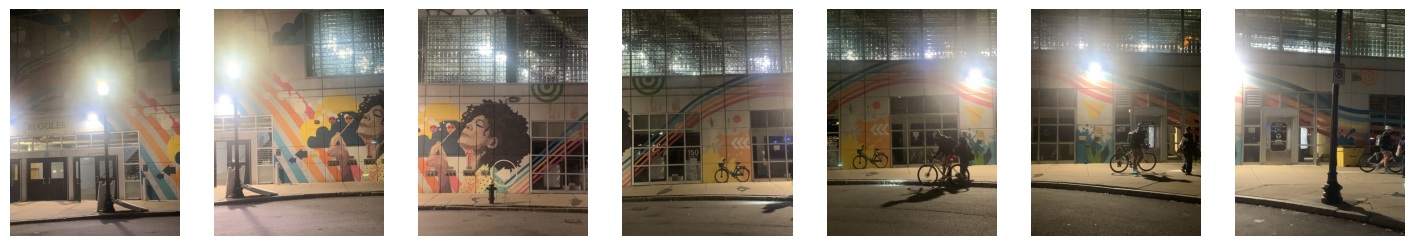

In [129]:
fig, ax = plt.subplots(1, len(mural), figsize=(18, 4))
for a, im in zip(ax, mural):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    a.axis('off')
plt.show()

In [130]:
from harris import harris

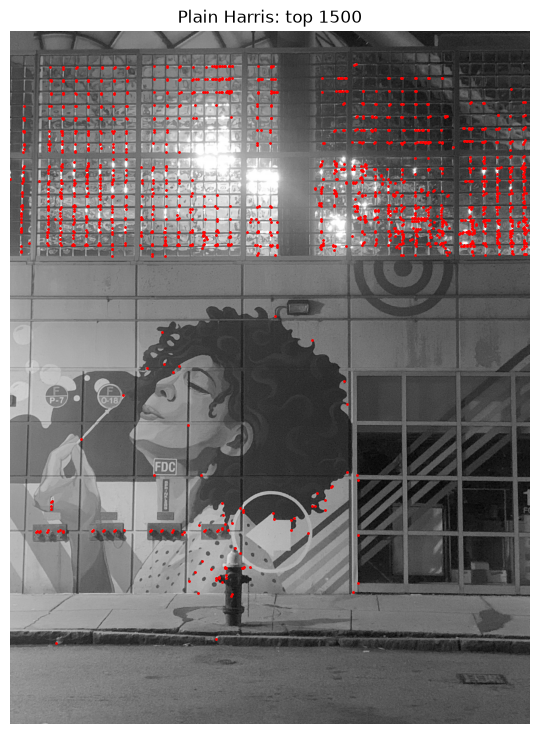

In [131]:
g = cv2.cvtColor(mural[2], cv2.COLOR_BGR2GRAY)
ys, xs, _ = harris(g, N=1500)

plt.figure(figsize=(7, 9))
plt.imshow(g, cmap='gray'); plt.plot(xs, ys, 'r.', ms=2)
plt.title('Plain Harris: top 1500'); plt.axis('off'); plt.show()

In [132]:
def harris_points_grid(gray, N=6000, tile=(12,9), sigma=1.0, hsize=5, thresh=0):
    ys, xs, _ = harris(gray, N=N, tile=list(tile), sigma=sigma, hsize=hsize, thresh=thresh)
    return np.column_stack([xs, ys])   

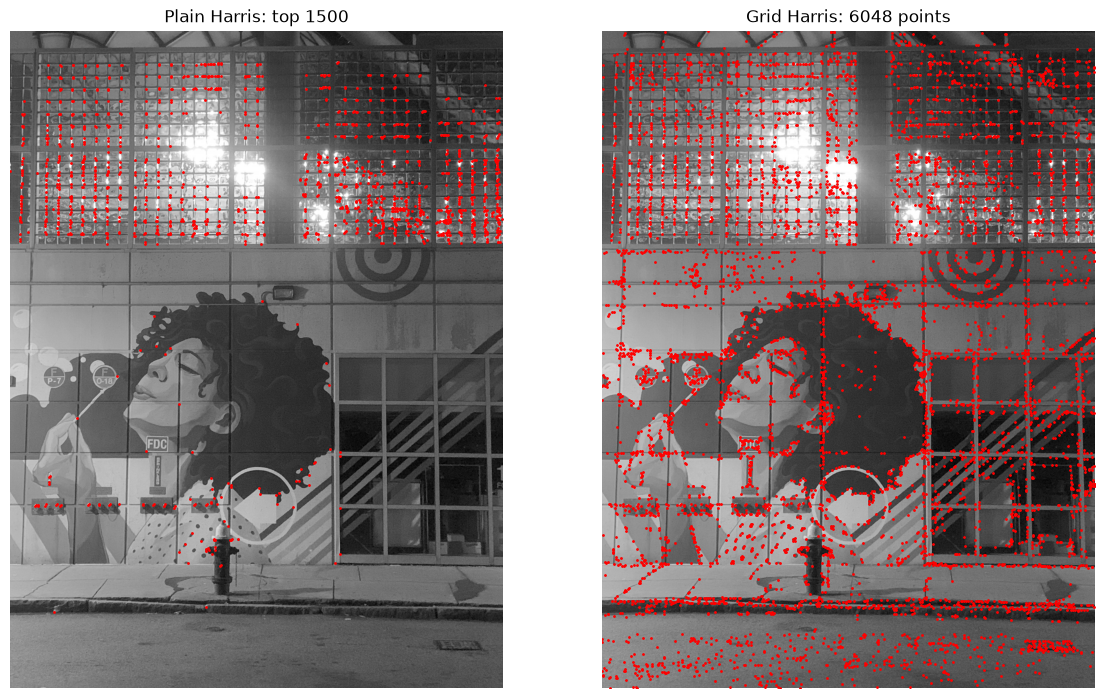

In [133]:
spread = harris_points_grid(g)

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
ax[0].imshow(g, cmap='gray'); ax[0].plot(xs, ys, 'r.', ms=2)
ax[0].set_title('Plain Harris: top 1500'); ax[0].axis('off')
ax[1].imshow(g, cmap='gray'); ax[1].plot(spread[:, 0], spread[:, 1], 'r.', ms=2)
ax[1].set_title(f'Grid Harris: {len(spread)} points'); ax[1].axis('off')
plt.show()

### Task 3: Harris feature distribution

With plain Harris (no tiling, top 1500 points), almost all corners landed on the glass blocks at the top of the image. They have very strong, high-contrast edges, so they dominate the response. The mural itself, which is the part we actually want to align, got very few points. A homography fit mostly to one region can be inaccurate everywhere else.

Using the tile option (8 × 6 grid) forces the detector to keep the best points in every region, so corners end up spread across the mural, the windows, the hydrant and the sidewalk. Some points also land on the road, which is weak texture and not part of the wall plane, but RANSAC rejects most of them later.

Effect of changing parameters:
- **N:** more points gives better coverage but slower matching, and fewer points makes the result less stable. With N = 500 the mural got noticeably fewer points, whereas with N=10000, the mural covered nearly everything, inlcuding the road.
- **tile:** a finer grid spreads points more evenly, a coarser grid lets them cluster again. With the 4 × 3 grid, the points clustered again on the glass blocks with gaps on the mural, while a fine 12 × 9 grid spread them evenly across the whole image.
- **sigma / hsize:** more smoothing removes noisy corners and keeps larger, more stable ones. The number of points stays fixed by N, but changing hsize (3 vs. 5) moves where they land, because the smoothing window changes the response map; hsize = 1 gave 0 points, since a single pixel’s gradient can never form a corner.”

In [134]:
sift = cv2.SIFT_create()

def features(img, **harris_args):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    pts = harris_points_grid(gray, **harris_args)
    kps = [cv2.KeyPoint(float(x), float(y), 16) for x, y in pts]  
    kps, des = sift.compute(gray, kps)   
    return kps, des

474 matches after ratio test


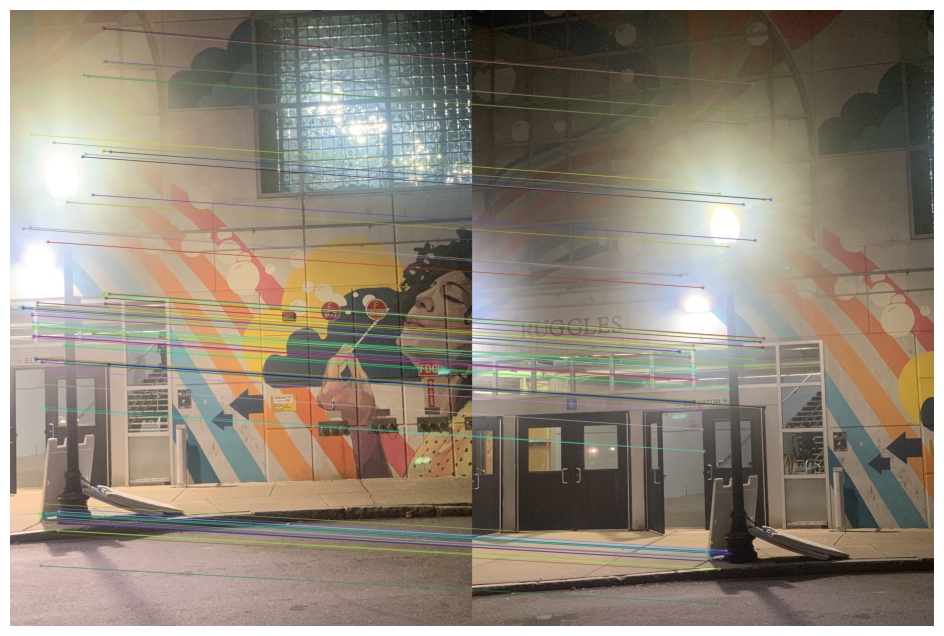

In [135]:
bf = cv2.BFMatcher(cv2.NORM_L2)

def match(desA, desB, ratio=0.75):
    pairs = bf.knnMatch(desB, desA, k=2)        
    return [m for m, n in pairs if m.distance < ratio * n.distance]

kA, dA = features(mural[0])
kB, dB = features(mural[1])
good = match(dA, dB)
print(len(good), 'matches after ratio test')

vis = cv2.drawMatches(mural[1], kB, mural[0], kA, good[:80], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

474 matches, 252 RANSAC inliers
[[ 8.93000e-01  1.70000e-02  4.98296e+02]
 [-8.00000e-02  9.54000e-01  1.47541e+02]
 [-0.00000e+00 -0.00000e+00  1.00000e+00]]


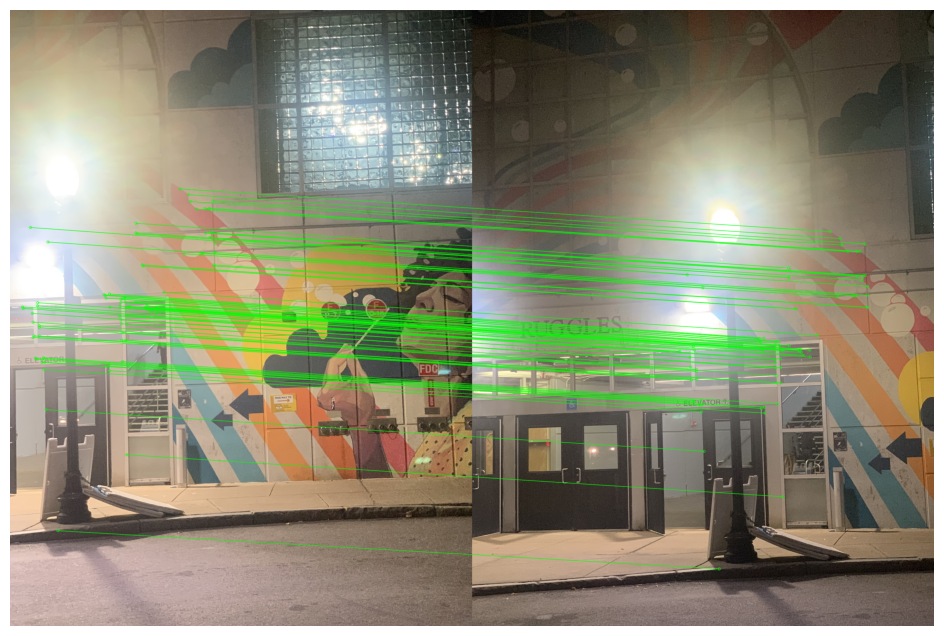

In [136]:
def pair_homography(kA, dA, kB, dB, ratio=0.75, reproj=4.0):
    good = match(dA, dB, ratio)
    if len(good) < 4:
        raise RuntimeError(f'only {len(good)} matches, need at least 4')
    src = np.float32([kB[m.queryIdx].pt for m in good])   
    dst = np.float32([kA[m.trainIdx].pt for m in good])   
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, reproj)
    inliers = mask.ravel().astype(bool)
    return H, good, inliers

H, good, inl = pair_homography(kA, dA, kB, dB)
print(len(good), 'matches,', inl.sum(), 'RANSAC inliers')
print(np.round(H, 3))

inlier_matches = [m for m, keep in zip(good, inl) if keep]
vis = cv2.drawMatches(mural[1], kB, mural[0], kA, inlier_matches[:80], None,
                      matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

In [137]:
def all_homographies(imgs, ratio=0.75, reproj=4.0, **harris_args):
    feats = [features(im, **harris_args) for im in imgs]
    Hs = [np.eye(3)]                              
    for i in range(len(imgs) - 1):
        (kA, dA), (kB, dB) = feats[i], feats[i+1]
        H, good, inl = pair_homography(kA, dA, kB, dB, ratio, reproj)
        print(f'pair {i}-{i+1}: {len(good)} matches, {inl.sum()} inliers')
        Hs.append(Hs[-1] @ H)                     
    ref = len(imgs) // 2
    Hinv = np.linalg.inv(Hs[ref])
    return [Hinv @ H for H in Hs]                 

Hs = all_homographies(mural)

pair 0-1: 474 matches, 252 inliers
pair 1-2: 359 matches, 283 inliers
pair 2-3: 275 matches, 167 inliers
pair 3-4: 352 matches, 199 inliers
pair 4-5: 192 matches, 79 inliers
pair 5-6: 137 matches, 56 inliers


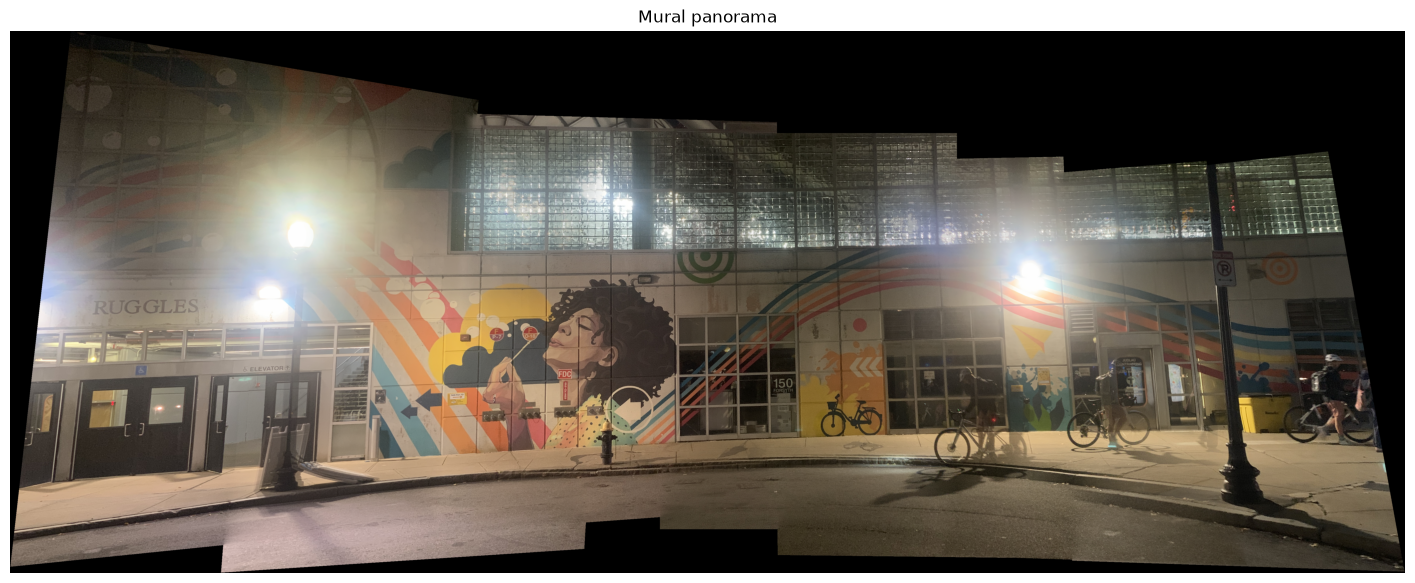

True

In [138]:
def warp_and_blend(imgs, Hs):
    
    corners = []
    for im, H in zip(imgs, Hs):
        h, w = im.shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        corners.append(cv2.perspectiveTransform(c, H))
    allc = np.concatenate(corners)
    xmin, ymin = np.floor(allc.min(0).ravel()).astype(int)
    xmax, ymax = np.ceil(allc.max(0).ravel()).astype(int)
    T = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1]], float)  
    W, Hh = xmax - xmin, ymax - ymin

    # 2. warp each image with a feathering weight
    acc = np.zeros((Hh, W, 3), np.float32)
    wsum = np.zeros((Hh, W, 1), np.float32)
    for im, H in zip(imgs, Hs):
        h, w = im.shape[:2]
        wt = cv2.distanceTransform(np.pad(np.ones((h-2, w-2), np.uint8), 1),
                                   cv2.DIST_L2, 3).astype(np.float32)  
        warped = cv2.warpPerspective(im.astype(np.float32), T @ H, (W, Hh))
        wwarp = cv2.warpPerspective(wt, T @ H, (W, Hh))[..., None]
        acc += warped * wwarp
        wsum += wwarp
    return (acc / np.maximum(wsum, 1e-6)).astype(np.uint8)

pano_mural = warp_and_blend(mural, Hs)
plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(pano_mural, cv2.COLOR_BGR2RGB)); plt.axis('off')
plt.title('Mural panorama'); plt.show()
cv2.imwrite('pano_mural.jpg', pano_mural)

### Task 4: Mural mosaic

All 7 images stitched into one panorama. Each neighbouring pair had plenty of RANSAC inliers, because the mural has many distinct features such as bubbles, stripes, signs and window frames. The camera only moved sideways along a flat wall, so one homography per pair is enough, and the mural lines up with no visible breaks.

The homography between images 1 and 2 showed a horizontal shift of about 500 px, plus a vertical shift of about 160 px and a slight rotation. So the phone was not held at exactly the same height and angle, and the homography corrected for that.

Artifacts:
- **Ghosting:** cyclists and pedestrians moved between shots, so they appear doubled or transparent. A homography can only model the static wall.
- **Parallax:** the road and sidewalk are not in the same plane as the wall, so they misalign slightly even where the mural is perfect.
- **Uneven borders:** the stepped black edges come from the height and tilt changes between photos, and from small errors adding up when homographies are chained.
- **Lens flare:** the street lamps wash out parts of the image and give few useful features.

In [139]:
def stitch_groups(imgs, ratio=0.75, reproj=4.0, min_inliers=10, **harris_args):
    feats = [features(im, **harris_args) for im in imgs]
    groups, cur, Hcur = [], [0], [np.eye(3)]
    for i in range(len(imgs) - 1):
        (kA, dA), (kB, dB) = feats[i], feats[i+1]
        good = match(dA, dB, ratio)
        H, n_in = None, 0
        if len(good) >= 4:
            src = np.float32([kB[m.queryIdx].pt for m in good])
            dst = np.float32([kA[m.trainIdx].pt for m in good])
            H, mask = cv2.findHomography(src, dst, cv2.RANSAC, reproj)
            n_in = int(mask.sum()) if mask is not None else 0
        print(f'pair {i+1}-{i+2}: {len(good)} matches, {n_in} inliers', '' if n_in >= min_inliers else '<- FAILED')
        if H is not None and n_in >= min_inliers:
            cur.append(i+1); Hcur.append(Hcur[-1] @ H)     
        else:
            groups.append((cur, Hcur)); cur, Hcur = [i+1], [np.eye(3)]  
    groups.append((cur, Hcur))

    results = []
    for idx, Hs in groups:
        Hinv = np.linalg.inv(Hs[len(Hs)//2])                 
        results.append(warp_and_blend([imgs[k] for k in idx], [Hinv @ H for H in Hs]))
        print('group', [k+1 for k in idx])
    return results

def show_all(results, name):
    for n, p in enumerate(results):
        plt.figure(figsize=(16, 6)); plt.imshow(cv2.cvtColor(p, cv2.COLOR_BGR2RGB))
        plt.axis('off'); plt.title(f'{name}: group {n+1}'); plt.show()
        cv2.imwrite(f'pano_{name}_{n+1}.jpg', p)

7 images: ['1.jpeg', '2.jpeg', '3.jpeg', '4.jpeg', '5.jpeg', '6.jpeg', '7.jpeg']


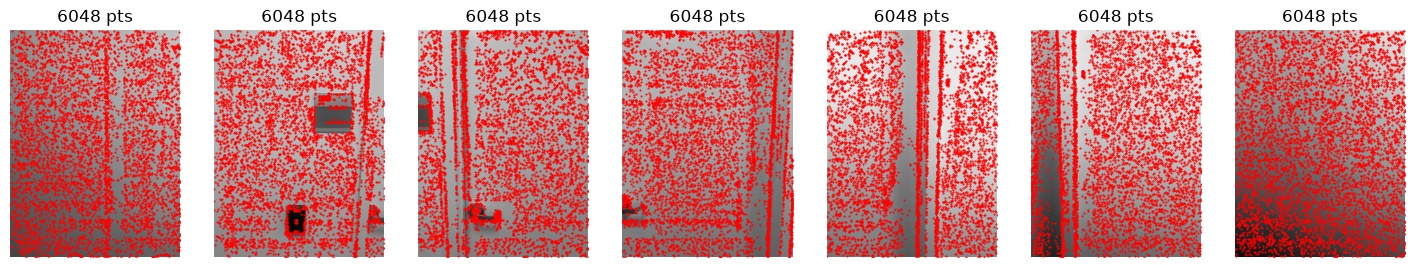

pair 1-2: 1 matches, 0 inliers <- FAILED
pair 2-3: 28 matches, 9 inliers <- FAILED
pair 3-4: 13 matches, 8 inliers <- FAILED
pair 4-5: 8 matches, 5 inliers <- FAILED
pair 5-6: 72 matches, 42 inliers 
pair 6-7: 2 matches, 0 inliers <- FAILED
group [1]
group [2]
group [3]
group [4]
group [5, 6]
group [7]


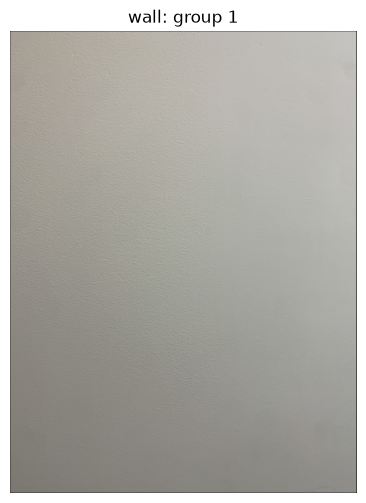

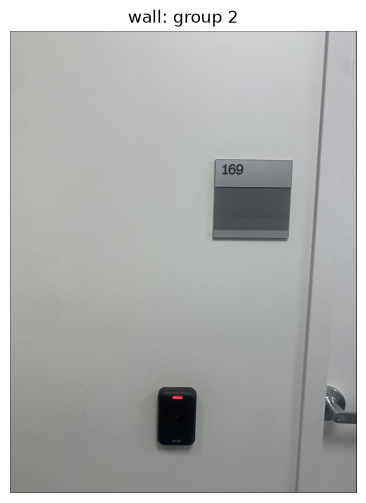

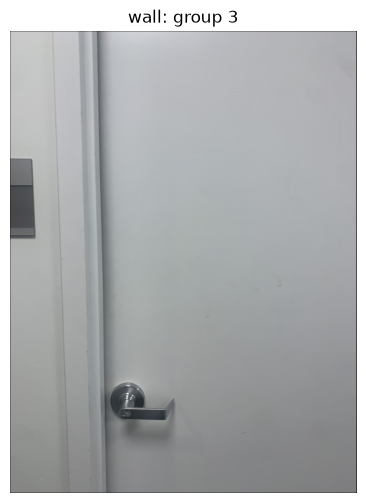

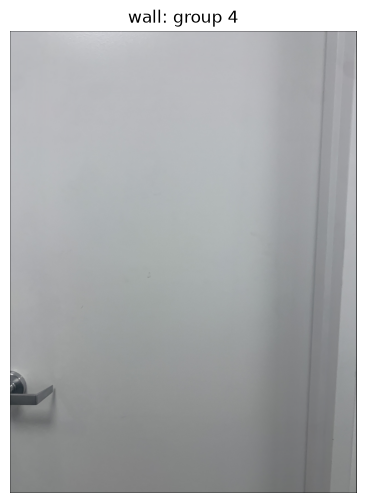

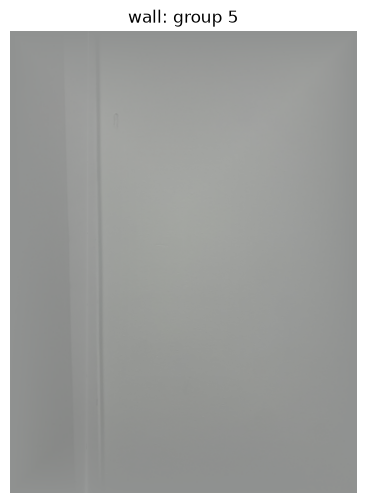

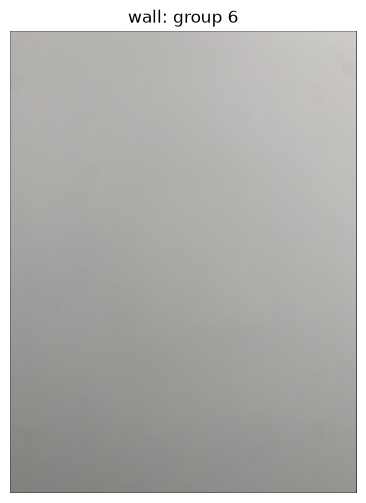

In [140]:
wall = load_images('data/wall')

fig, ax = plt.subplots(1, len(wall), figsize=(18, 4))
for a, im in zip(ax, wall):
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    p = harris_points_grid(gray)
    a.imshow(gray, cmap='gray'); a.plot(p[:, 0], p[:, 1], 'r.', ms=1)
    a.set_title(f'{len(p)} pts'); a.axis('off')
plt.show()

wall_results = stitch_groups(wall)
show_all(wall_results, 'wall')

### Task 5: Plain wall (about 50% overlap)

As suggested by the professor, a plain painted wall was used instead of a textured cinder block wall. Even with about 50% overlap, the mosaic mostly failed:

pair 1-2: 1 matches, 0 inliers <- FAILED

pair 2-3: 35 matches, 11 inliers 

pair 3-4: 8 matches, 4 inliers <- FAILED

pair 4-5: 9 matches, 6 inliers <- FAILED

pair 5-6: 10 matches, 5 inliers <- FAILED

pair 6-7: 1 matches, 0 inliers <- FAILED

The detector still returned thousands of points per image, but on the blank areas these are paint texture and camera noise, not real corners. All those patches look almost the same, so their descriptors cannot be told apart and the ratio test removes nearly every match. Only pair [2-3] linked (11 inliers), because both images contain the door handle and door frame, which are distinctive.

Conclusion: Harris-based stitching needs texture. Overlap alone is not enough. The shared region must contain unique features.

6 images: ['1.jpeg', '2.jpeg', '3.jpeg', '4.jpeg', '5.jpeg', '6.jpeg']
--- default settings ---
pair 1-2: 29 matches, 19 inliers 
pair 2-3: 30 matches, 14 inliers 
pair 3-4: 7 matches, 4 inliers <- FAILED
pair 4-5: 5 matches, 4 inliers <- FAILED
pair 5-6: 9 matches, 4 inliers <- FAILED
group [1, 2, 3]
group [4]
group [5]
group [6]


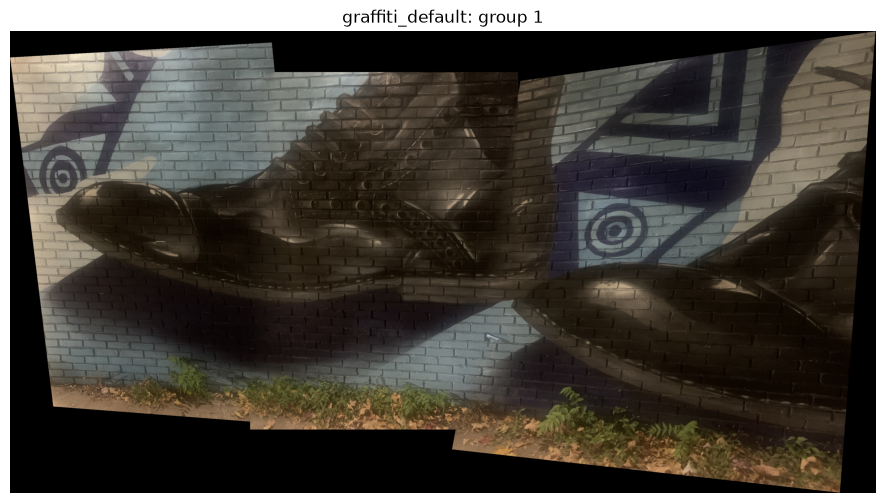

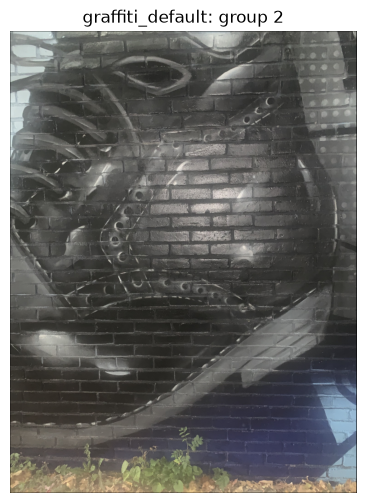

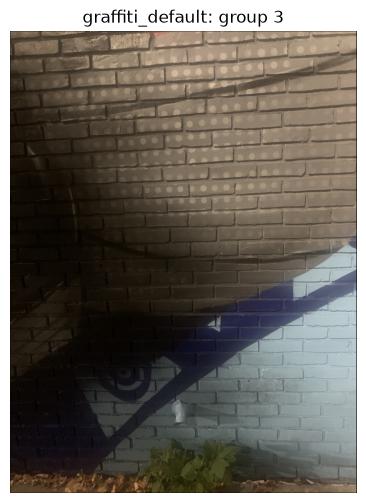

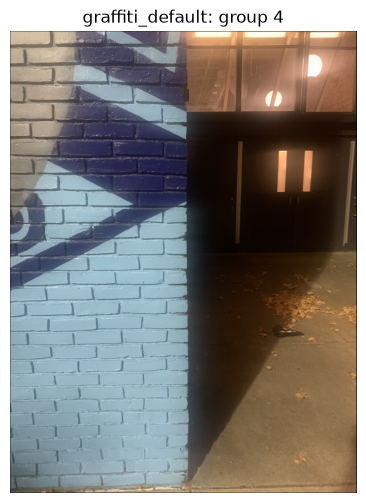

--- looser settings ---
pair 1-2: 39 matches, 30 inliers 
pair 2-3: 47 matches, 19 inliers 
pair 3-4: 7 matches, 0 inliers <- FAILED
pair 4-5: 11 matches, 6 inliers 
pair 5-6: 43 matches, 8 inliers 
group [1, 2, 3]
group [4, 5, 6]


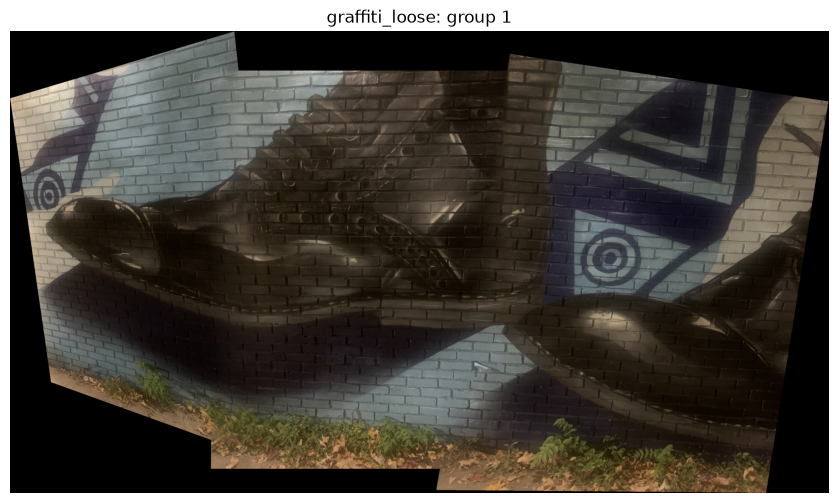

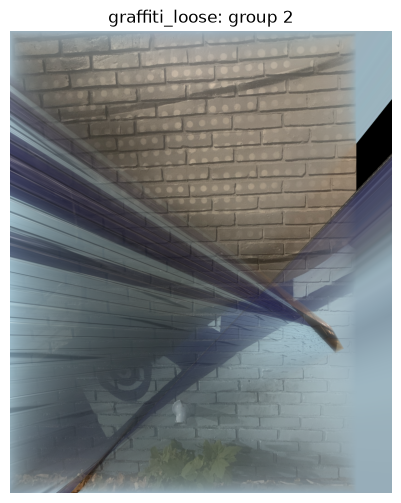

In [141]:
graffiti = load_images('data/graffiti')

print('--- default settings ---')
g_default = stitch_groups(graffiti)
show_all(g_default, 'graffiti_default')

print('--- looser settings ---')
g_loose = stitch_groups(graffiti, ratio=0.8, reproj=6.0, min_inliers=6,
                        tile=(10, 8), N=20000)
show_all(g_loose, 'graffiti_loose')

### Task 6: Graffiti with about 15% overlap

Default settings (ratio 0.75, RANSAC threshold 4):

pair 1-2: 29 matches, 19 inliers 

pair 2-3: 30 matches, 14 inliers 

pair 3-4: 7 matches, 4 inliers <- FAILED

pair 4-5: 5 matches, 4 inliers <- FAILED

pair 5-6: 9 matches, 4 inliers <- FAILED

With only about 15% overlap, the shared strip between neighbours is thin, so far fewer matches survive. Images 1-2-3 still stitched cleanly because their shared strips contain distinctive graffiti shapes. Pair 3-4 failed because that strip is mostly repeated bricks and dark paint, which look alike. Pair 5-6 failed because image 6 is the end of the wall with a doorway, a different surface with almost nothing in common.

Looser settings (ratio 0.8, RANSAC threshold 6, tile 10 × 8, N = 20000):

pair 1-2: 24 matches, 18 inliers 

pair 2-3: 27 matches, 13 inliers 

pair 3-4: 6 matches, 0 inliers <- FAILED

pair 4-5: 3 matches, 0 inliers <- FAILED

pair 5-6: 7 matches, 4 inliers <- FAILED

Loosening the settings keeps more matches and accepts less exact ones, which can rescue weak pairs. The tradeoff is that more wrong matches get through, which can bend or distort the mosaic.

Conclusion: low overlap partly works. It succeeds only where the thin shared strip has unique features, and breaks where it is repetitive or featureless.